# 03 · So sánh mô hình bằng purged walk-forward
Đặc trưng tin tức ở đây là **proxy thô** (khối lượng và tỷ lệ từ khóa tiêu cực) để thử cơ chế; không phải chỉ số sợ hãi LLM. Mục đích: chọn *họ mô hình* dựa trên dữ liệu, không kết luận về sức mạnh dự báo của tin tức.

In [1]:
import sys, warnings
sys.path.insert(0, '.')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from _common import *
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3})
news, px, tg = load()
vn30 = px[px.ticker == 'VN30'].set_index('date').sort_index()
print(f'news {len(news):,} | price rows {len(px):,} | targets {len(tg):,}')
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss
import lightgbm as lgb
import statsmodels.api as sm

news 122,557 | price rows 80,599 | targets 1,704


In [2]:
pf = price_features(px); nf = news_daily_features(news)
nf = nf.reindex(pf.index).fillna(0)
nf['ln_n'] = np.log1p(nf.n_all); nf['ln_mkt'] = np.log1p(nf.n_market)
nf['ln_n_z'] = (nf.ln_n - nf.ln_n.rolling(60).mean()) / nf.ln_n.rolling(60).std()
nf['neg_z'] = (nf.neg_rate - nf.neg_rate.rolling(60).mean()) / nf.neg_rate.rolling(60).std()
nf['neg_5d'] = nf.neg_rate.rolling(5).mean()
PRICE = ['ret1', 'ret5', 'ret20', 'vol20', 'vol5_over_20', 'volu_z', 'dd60']
NEWS = ['ln_n_z', 'neg_z', 'neg_5d', 'after_hours']
D = tg.set_index('date').join(pf).join(nf[NEWS]).dropna(subset=PRICE + NEWS + ['y_up'])
print(D.shape, D.index.min().date(), D.index.max().date())

(1645, 16) 2020-04-01 2026-11-02


In [3]:
def folds(D, first_train=750, test_len=63, embargo=5):
    idx = D.index; t_end = D.t_end
    i = first_train
    while i < len(idx):
        test = idx[i:i + test_len]
        t0 = test[0]
        # purge: loại mẫu huấn luyện có cửa sổ nhãn chạm vào/trùng test; thêm embargo
        train = idx[:i - embargo]
        train = train[t_end.loc[train].values < np.datetime64(t0)]
        yield train, test
        i += test_len

def make(name):
    if name == 'logit_price':   return PRICE, make_pipeline(StandardScaler(), LogisticRegression(C=.1, max_iter=500)), 'lin'
    if name == 'enet_price_news': return PRICE + NEWS, make_pipeline(StandardScaler(), LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=.5, C=.1, max_iter=3000)), 'lin'
    if name == 'lgbm':          return PRICE + NEWS, lgb.LGBMClassifier(n_estimators=150, max_depth=2, num_leaves=4, learning_rate=.03, subsample=.8, subsample_freq=1, colsample_bytree=.8, min_child_samples=40, reg_lambda=5, verbose=-1, random_state=0), 'tree'
    if name == 'mlp':           return PRICE + NEWS, make_pipeline(StandardScaler(), MLPClassifier((32, 16), alpha=1e-2, max_iter=600, early_stopping=False, random_state=0)), 'nn'

MODELS = ['logit_price', 'enet_price_news', 'lgbm', 'mlp']
def run(target):
    out = {m: [] for m in MODELS}; base = []; dates = []
    for tr, te in folds(D):
        ytr, yte = D.loc[tr, target].values, D.loc[te, target].values
        base.append(np.full(len(te), ytr.mean())); dates.append(te)
        for m in MODELS:
            cols, mod, _ = make(m)
            mod.fit(D.loc[tr, cols].values, ytr)
            out[m].append(mod.predict_proba(D.loc[te, cols].values)[:, 1])
    idx = np.concatenate([d.values for d in dates])
    P = pd.DataFrame({m: np.concatenate(v) for m, v in out.items()}, index=idx); P['base'] = np.concatenate(base)
    P['y'] = D.loc[idx, target].values
    return P

res = {t: run(t) for t in ['y_drop', 'y_up']}
print({t: len(P) for t, P in res.items()}, 'quan sát OOS')

{'y_drop': 895, 'y_up': 895} quan sát OOS


## 1. Chỉ số ngoài mẫu

In [4]:
def table(P):
    rows = []
    for m in MODELS + ['base']:
        p = P[m].values; y = P.y.values
        bs = brier_score_loss(y, p); bs0 = brier_score_loss(y, P.base.values)
        auc = roc_auc_score(y, p) if m != 'base' else .5
        thr = np.quantile(p, 1 - y.mean()) if m != 'base' else 1.1
        rows.append((m, bs, 1 - bs / bs0, auc, mcc(y, (p >= thr).astype(int))))
    return pd.DataFrame(rows, columns=['model', 'Brier', 'BSS vs base', 'AUC', 'MCC']).set_index('model').round(4)
for t, P in res.items():
    print('==', t, '(prevalence OOS = %.3f)' % P.y.mean()); print(table(P))

== y_drop (prevalence OOS = 0.166)
                  Brier  BSS vs base     AUC     MCC
model                                               
logit_price      0.1401       0.0001  0.5082  0.0096
enet_price_news  0.1413      -0.0084  0.4892  0.0016
lgbm             0.1419      -0.0126  0.5429  0.0177
mlp              0.2108      -0.5051  0.4701 -0.0790
base             0.1401       0.0000  0.5000  0.0000
== y_up (prevalence OOS = 0.569)
                  Brier  BSS vs base     AUC     MCC
model                                               
logit_price      0.2458       0.0018  0.5145  0.0479
enet_price_news  0.2470      -0.0031  0.4925 -0.0432
lgbm             0.2516      -0.0217  0.5012 -0.0113
mlp              0.3507      -0.4243  0.5150  0.0161
base             0.2463       0.0000  0.5000  0.0000


## 2. Kiểm định thống kê (HAC cho chồng lấn 5 phiên)

In [5]:
def cw_prob(P, small, big, lags=4):
    y = P.y.values; p0 = P[small].values; p1 = P[big].values
    f = (y - p0) ** 2 - ((y - p1) ** 2 - (p0 - p1) ** 2)  # Clark-West adj (cho mô hình lồng nhau)
    m = sm.OLS(f, np.ones_like(f)).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    return m.params[0], m.tvalues[0], stats.norm.sf(m.tvalues[0])

def dm_prob(P, a, b, lags=4):
    y = P.y.values; d = (y - P[a].values) ** 2 - (y - P[b].values) ** 2
    m = sm.OLS(d, np.ones_like(d)).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    return m.params[0], m.tvalues[0], 2 * stats.norm.sf(abs(m.tvalues[0]))

from scipy import stats
rows = []
for t, P in res.items():
    rows.append((t, 'CW: logit_price ⊂ enet_price_news', *cw_prob(P, 'logit_price', 'enet_price_news')))
    rows.append((t, 'CW: base vs logit_price', *cw_prob(P.assign(b0=P.base), 'b0', 'logit_price')))
    rows.append((t, 'DM: enet_price_news vs lgbm', *dm_prob(P, 'enet_price_news', 'lgbm')))
    rows.append((t, 'DM: enet_price_news vs mlp', *dm_prob(P, 'enet_price_news', 'mlp')))
print(pd.DataFrame(rows, columns=['target', 'test', 'mean_stat', 't_HAC', 'p']).round(4).to_string(index=False))

target                              test  mean_stat   t_HAC      p
y_drop CW: logit_price ⊂ enet_price_news    -0.0006 -0.8823 0.8112
y_drop           CW: base vs logit_price     0.0014  1.0987 0.1360
y_drop       DM: enet_price_news vs lgbm    -0.0006 -0.2501 0.8025
y_drop        DM: enet_price_news vs mlp    -0.0696 -6.8919 0.0000
  y_up CW: logit_price ⊂ enet_price_news    -0.0006 -0.5033 0.6926
  y_up           CW: base vs logit_price     0.0017  1.0113 0.1559
  y_up       DM: enet_price_news vs lgbm    -0.0046 -1.2687 0.2045
  y_up        DM: enet_price_news vs mlp    -0.1037 -7.9829 0.0000


## 2b. Công bằng với mạng nơ-ron: MLP điều hòa mạnh
MLP ở trên chưa tinh chỉnh. Thử cấu hình nhỏ và alpha lớn để loại trừ khả năng kết quả xấu chỉ do cấu hình.

In [6]:
def run_mlp(target, hidden, alpha):
    ps, ys, ix = [], [], []
    for tr, te in folds(D):
        cols = PRICE + NEWS
        mod = make_pipeline(StandardScaler(), MLPClassifier(hidden, alpha=alpha, max_iter=800, early_stopping=True, validation_fraction=.2, n_iter_no_change=15, random_state=0))
        mod.fit(D.loc[tr, cols].values, D.loc[tr, target].values)
        ps.append(mod.predict_proba(D.loc[te, cols].values)[:, 1]); ix.append(te.values)
    return np.concatenate(ix), np.concatenate(ps)
rows = []
for t in ['y_drop', 'y_up']:
    P = res[t]
    for hidden, alpha in [((32, 16), 1e-2), ((8,), 1.0), ((4,), 10.0)]:
        ix, p = run_mlp(t, hidden, alpha)
        y = P.loc[ix, 'y'].values; b = P.loc[ix, 'base'].values
        rows.append((t, str(hidden), alpha, round(1 - brier_score_loss(y, p) / brier_score_loss(y, b), 4), round(roc_auc_score(y, p), 3), round(p.std(), 3)))
print(pd.DataFrame(rows, columns=['target', 'hidden', 'alpha', 'BSS vs base', 'AUC', 'std(p̂)']).to_string(index=False))

target   hidden  alpha  BSS vs base   AUC  std(p̂)
y_drop (32, 16)   0.01      -0.1960 0.553    0.078
y_drop     (8,)   1.00      -0.1112 0.504    0.113
y_drop     (4,)  10.00      -0.4112 0.510    0.164
  y_up (32, 16)   0.01      -0.0299 0.517    0.082
  y_up     (8,)   1.00      -0.1050 0.525    0.160
  y_up     (4,)  10.00      -0.0871 0.485    0.052


## 3. Ổn định theo thời gian và độ lệch của từng họ mô hình

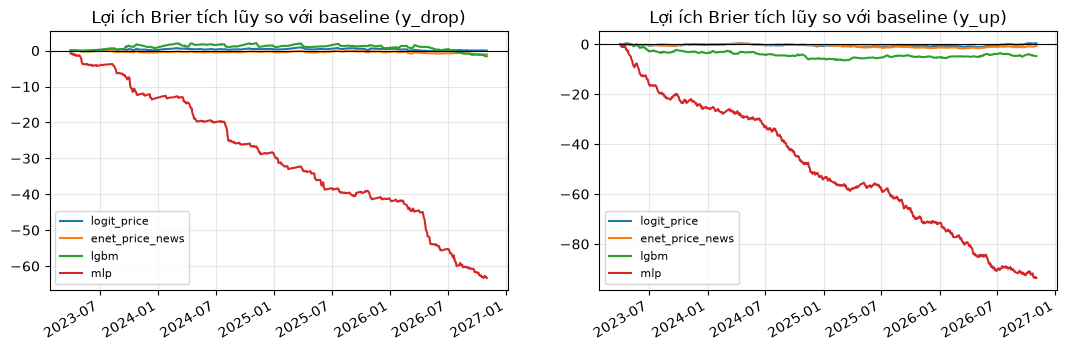

BSS theo năm (OOS):
target  year   n  logit_price  enet_price_news   lgbm    mlp
y_drop  2023 191        0.006           -0.019  0.033 -0.495
y_drop  2024 250        0.007            0.003  0.012 -0.545
y_drop  2025 249        0.003            0.000 -0.013 -0.407
y_drop  2026 205       -0.011           -0.017 -0.061 -0.558
  y_up  2023 191       -0.006           -0.003 -0.076 -0.545
  y_up  2024 250       -0.006           -0.005 -0.035 -0.453
  y_up  2025 249        0.000           -0.015  0.010 -0.314
  y_up  2026 205        0.019            0.011  0.007 -0.401


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (t, P) in zip(axes, res.items()):
    for m in MODELS:
        d = (P.y - P.base) ** 2 - (P.y - P[m]) ** 2
        d.cumsum().plot(ax=ax, label=m)
    ax.axhline(0, color='k', lw=.8); ax.set_title(f'Lợi ích Brier tích lũy so với baseline ({t})'); ax.legend(fontsize=8)
savefig(fig, 'nb03_cum_brier'); plt.show()
yearly = []
for t, P in res.items():
    for y_, g in P.groupby(pd.DatetimeIndex(P.index).year):
        row = {'target': t, 'year': y_, 'n': len(g)}
        for m in MODELS: row[m] = round(1 - brier_score_loss(g.y, g[m]) / brier_score_loss(g.y, g.base), 3)
        yearly.append(row)
print('BSS theo năm (OOS):'); print(pd.DataFrame(yearly).to_string(index=False))

                 y_drop   y_up
std(p̂)                       
logit_price       0.036  0.035
enet_price_news   0.040  0.036
lgbm              0.075  0.079
mlp               0.241  0.332


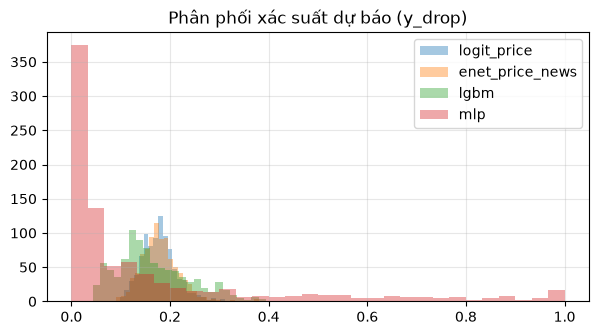

In [8]:
# Độ nhạy phương sai: spread xác suất dự báo cho từng họ mô hình
print(pd.DataFrame({t: P[MODELS].std() for t, P in res.items()}).round(3).rename_axis('std(p̂)'))
fig, ax = plt.subplots(figsize=(7, 3.5))
for m in MODELS: ax.hist(res['y_drop'][m], bins=30, alpha=.4, label=m)
ax.set_title('Phân phối xác suất dự báo (y_drop)'); ax.legend(); savefig(fig, 'nb03_prob_dist'); plt.show()

In [9]:
n_oos = len(res['y_drop']); infl = 3.48
def min_detectable_r(n_eff, alpha=.05, power=.8):
    return np.tanh((stats.norm.ppf(1 - alpha) + stats.norm.ppf(power)) / np.sqrt(n_eff - 3))
print(f'OOS = {n_oos} phiên (~{n_oos/5:.0f} cửa sổ độc lập, n_eff~{n_oos/infl:.0f}); r_min (80% power) ≈ {min_detectable_r(int(n_oos/infl)):.2f}')

OOS = 895 phiên (~179 cửa sổ độc lập, n_eff~257); r_min (80% power) ≈ 0.15


## Kết luận từ notebook 03
- Không mô hình nào có lợi ích ngoài mẫu đáng kể so với baseline; điều này được kỳ vọng vì chỉ dùng đặc trưng giá và proxy tin rất thô, và vì OOS chỉ có vài trăm quan sát hiệu dụng (sức mạnh thấp).
- Điều phân biệt các *họ mô hình* là độ ổn định, không phải độ chính xác: logistic điều hòa gần baseline; cây nông lệch nhẹ; MLP quá tự tin (std p̂ lớn), tệ hơn rõ rệt, và vẫn kém ngay cả khi điều hòa mạnh (xem 2b).
- Do đó proxy tin tức ở đây không được diễn giải là bằng chứng về sức mạnh dự báo của chỉ số sợ hãi LLM.